**Autores:** Jesús Moreno Cruz y Corro

# Datos Faltantes

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [3]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
270,0.005383,0.050680,0.030440,0.083844,-0.037344,-0.047347,0.015505,-0.039493,0.008641,0.015491,202.0
351,-0.085430,0.050680,-0.040696,-0.033213,-0.081374,-0.069580,-0.006584,-0.039493,-0.057803,-0.042499,71.0
434,0.016281,-0.044642,0.001339,0.008101,0.005311,0.010899,0.030232,-0.039493,-0.045424,0.032059,49.0
405,0.048974,0.050680,0.123131,0.083844,-0.104765,-0.100895,-0.069172,-0.002592,0.036644,-0.030072,281.0
350,-0.027310,0.050680,0.060618,0.107944,0.012191,-0.017598,-0.002903,-0.002592,0.070207,0.135612,243.0
164,0.045341,-0.044642,-0.019140,0.021872,0.027326,-0.013527,0.100183,-0.039493,0.017765,-0.013504,214.0
417,-0.052738,-0.044642,0.071397,-0.074527,-0.015328,-0.001314,0.004460,-0.021412,-0.046883,0.003064,55.0
243,0.016281,0.050680,-0.046085,0.011544,-0.033216,-0.016032,-0.010266,-0.002592,-0.043984,-0.042499,47.0
59,0.063504,0.050680,-0.025607,0.011544,0.064477,0.048477,0.030232,-0.002592,0.038394,0.019633,170.0
401,0.016281,-0.044642,-0.045007,-0.057313,-0.034592,-0.053923,0.074412,-0.076395,-0.042571,0.040343,93.0


In [4]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [5]:
# Ejercicio 1: valores faltantes por columna
faltantes = data.isnull().sum()
porcentaje = (faltantes / len(data) * 100).round(2)
pd.DataFrame({'faltantes': faltantes, 'porcentaje': porcentaje})

,faltantes,porcentaje
age,0,0.00
sex,0,0.00
bmi,44,9.95
bp,44,9.95
s1,0,0.00
s2,0,0.00
s3,0,0.00
s4,0,0.00
s5,0,0.00
s6,0,0.00


**Respuesta:** hay **44 valores faltantes en `bmi`** y **44 en `bp`**, es decir, el 9.95 % de las 442 filas en cada una. El resto de columnas no tiene faltantes.

### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [6]:
# Ejercicio 2: imputación simple (media) de 'bmi'
imputador_media = SimpleImputer(strategy='mean')
data_media = data.copy()
data_media['bmi'] = imputador_media.fit_transform(data[['bmi']]).ravel()

print('Media usada para imputar bmi:', round(imputador_media.statistics_[0], 4))
print('Valores faltantes en bmi después de imputar:', data_media['bmi'].isnull().sum())

Media usada para imputar bmi: -0.0002
Valores faltantes en bmi después de imputar: 0


**Respuesta:** la media usada para imputar `bmi` es **-0.0002** (los datos ya vienen estandarizados). Después de imputar, `bmi` no tiene valores faltantes.

### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [7]:
# Ejercicio 3: KNNImputer en 'bmi' y 'bp' vs. imputación por media
imputador_knn = KNNImputer(n_neighbors=5)
data_knn = data.copy()
data_knn[['bmi', 'bp']] = imputador_knn.fit_transform(data[['bmi', 'bp']])

imputador_media_2 = SimpleImputer(strategy='mean')
data_media2 = pd.DataFrame(
    imputador_media_2.fit_transform(data[['bmi', 'bp']]),
    columns=['bmi', 'bp'],
    index=data.index,
)

# Solo las filas que tenían algún valor simulado como faltante
mascara = data[['bmi', 'bp']].isnull().any(axis=1)
comparacion = pd.DataFrame({
    'bmi_media': data_media2.loc[mascara, 'bmi'],
    'bmi_knn': data_knn.loc[mascara, 'bmi'],
    'bp_media': data_media2.loc[mascara, 'bp'],
    'bp_knn': data_knn.loc[mascara, 'bp'],
}).round(4)
print('Filas imputadas:', mascara.sum())
print(comparacion.head(10))

resumen = pd.concat({
    'original (sin NaN)': data[['bmi', 'bp']].agg(['mean', 'std']),
    'imputación media': data_media2[['bmi', 'bp']].agg(['mean', 'std']),
    'imputación KNN': data_knn[['bmi', 'bp']].agg(['mean', 'std']),
})
print(resumen.round(4))

Filas imputadas: 83
    bmi_media  bmi_knn  bp_media  bp_knn
1     -0.0515  -0.0515    0.0005  0.0040
9     -0.0002  -0.0161   -0.0332 -0.0332
14    -0.0256  -0.0256    0.0005 -0.0183
17     0.0121   0.0121    0.0005 -0.0077
23     0.0606   0.0606    0.0005  0.0480
30    -0.0002  -0.0002    0.0005  0.0005
39    -0.0002  -0.0002    0.0005  0.0005
55    -0.0002   0.0000   -0.0367 -0.0367
63    -0.0375  -0.0375    0.0005 -0.0114
70    -0.0002  -0.0138   -0.0126 -0.0126
                            bmi      bp
original (sin NaN) mean -0.0002  0.0005
                   std   0.0470  0.0480
imputación media   mean -0.0002  0.0005
                   std   0.0446  0.0456
imputación KNN     mean  0.0002  0.0003
                   std   0.0454  0.0463


**Respuesta:** se imputaron 83 filas (44 por `bmi`, 44 por `bp`, algunas en ambas). Comparación:

- **Media:** todos los valores imputados son idénticos (-0.0002 en `bmi`, 0.0005 en `bp`).
- **KNN:** cada valor depende de los 5 vecinos más parecidos en `bmi` y `bp`, por lo que varía de fila a fila.
- **Desviación estándar de `bmi`:** original 0.0470, media 0.0446, KNN 0.0454. En `bp`: original 0.0480, media 0.0456, KNN 0.0463.

La imputación por media reduce más la dispersión; KNN queda más cerca de la distribución original en ambas columnas.

### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

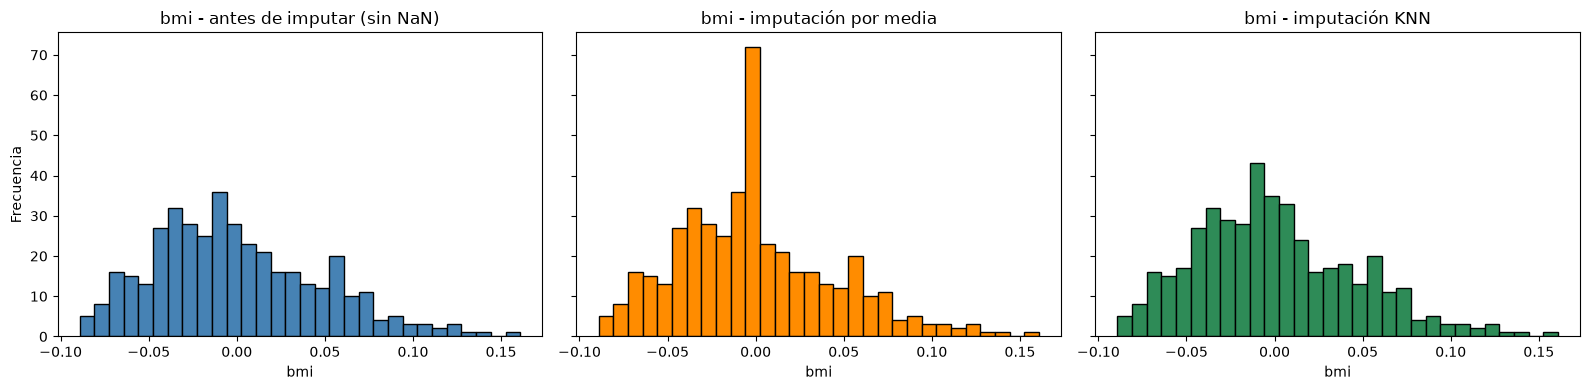

In [8]:
# Ejercicio 4: histogramas de 'bmi' antes y después de la imputación
fig, ejes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

ejes[0].hist(data['bmi'].dropna(), bins=30, color='steelblue', edgecolor='black')
ejes[0].set_title('bmi - antes de imputar (sin NaN)')

ejes[1].hist(data_media2['bmi'], bins=30, color='darkorange', edgecolor='black')
ejes[1].set_title('bmi - imputación por media')

ejes[2].hist(data_knn['bmi'], bins=30, color='seagreen', edgecolor='black')
ejes[2].set_title('bmi - imputación KNN')

for ax in ejes:
    ax.set_xlabel('bmi')
ejes[0].set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

**Respuesta:** los 398 valores observados de `bmi` se mantienen en los tres histogramas. La media coloca los 44 valores imputados en un mismo punto (la media de la columna), lo que genera un pico en esa zona. KNN reparte esos 44 valores según sus vecinos, por lo que no aparece ese pico único.